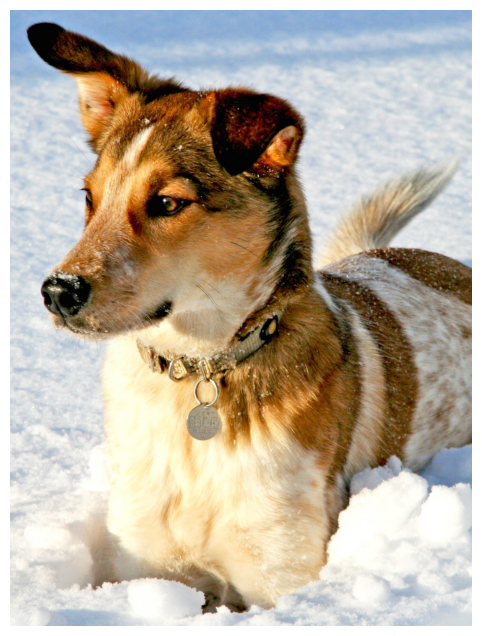

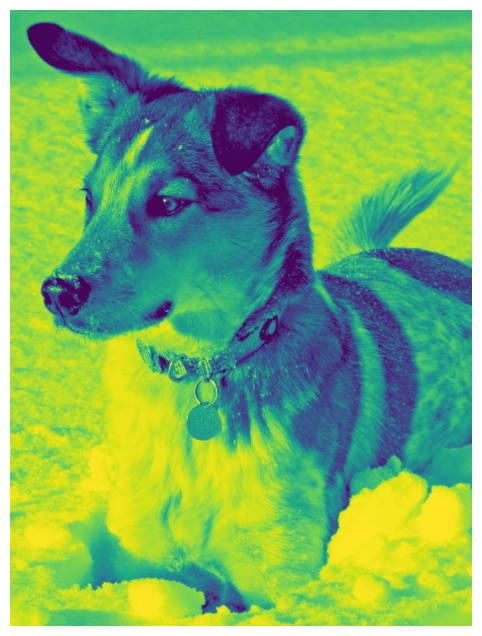

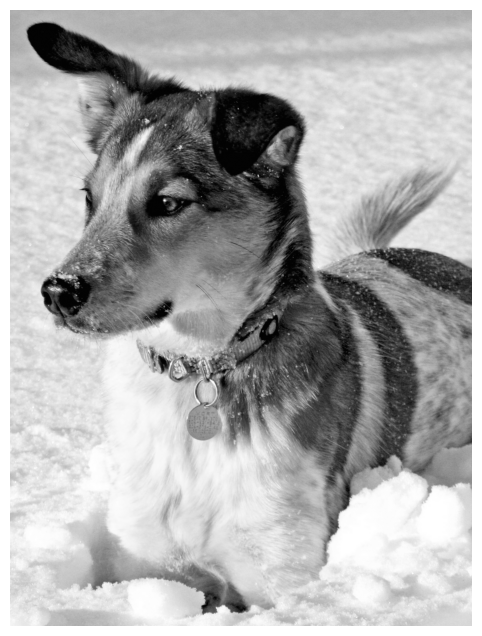

In [1]:
from matplotlib.image import imread
import matplotlib.pyplot as plt
import numpy as np
import os
plt.rcParams['figure.figsize'] = [16, 8]


A = imread(os.path.join('..','DATA','dog.jpg'))

plt.imshow(A)
plt.axis('off')
plt.show()

X = np.mean(A, -1); # Convert RGB to grayscale

img = plt.imshow(X)
#img.set_cmap('gray')
plt.axis('off')
plt.show()

img = plt.imshow(X)
img.set_cmap('gray')
plt.axis('off')
plt.show()

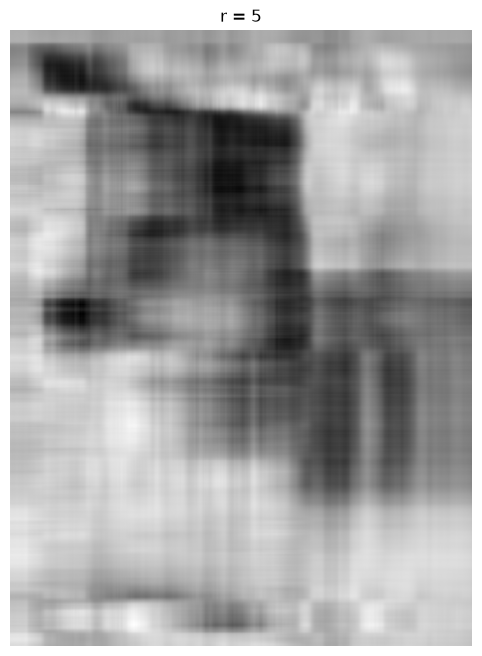

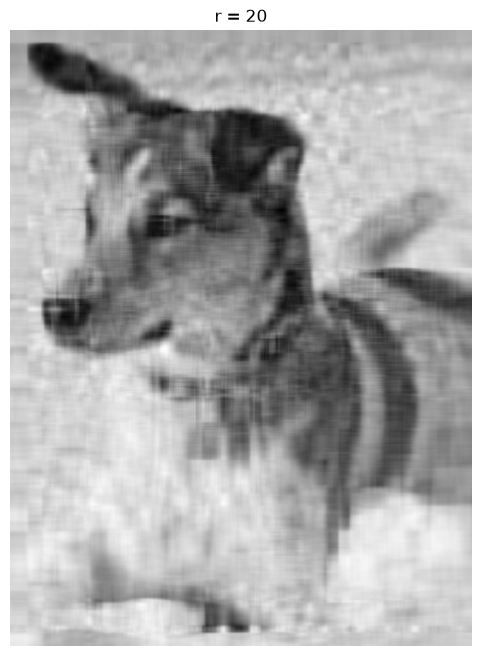

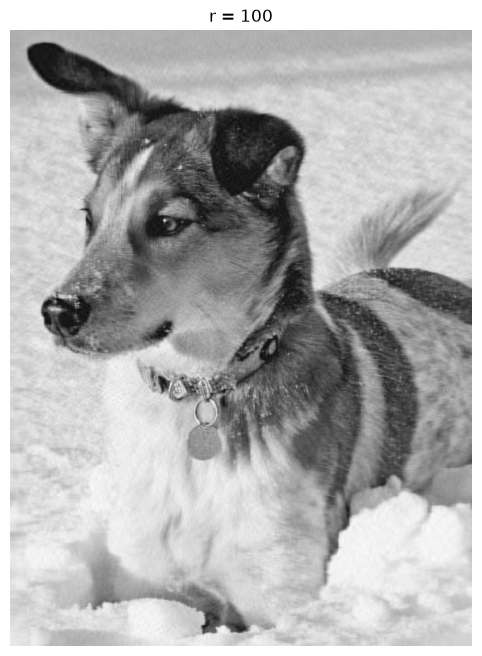

In [2]:
#full_matrices=False performs the economy SVD
U, S, VT = np.linalg.svd(X,full_matrices=False)
S = np.diag(S)

j = 0
for r in (5, 20, 100):
    # Construct approximate image
    Xapprox = U[:,:r] @ S[0:r,:r] @ VT[:r,:]
    plt.figure(j+1)
    j += 1
    img = plt.imshow(Xapprox)
    img.set_cmap('gray')
    plt.axis('off')
    plt.title('r = ' + str(r))
    plt.show()

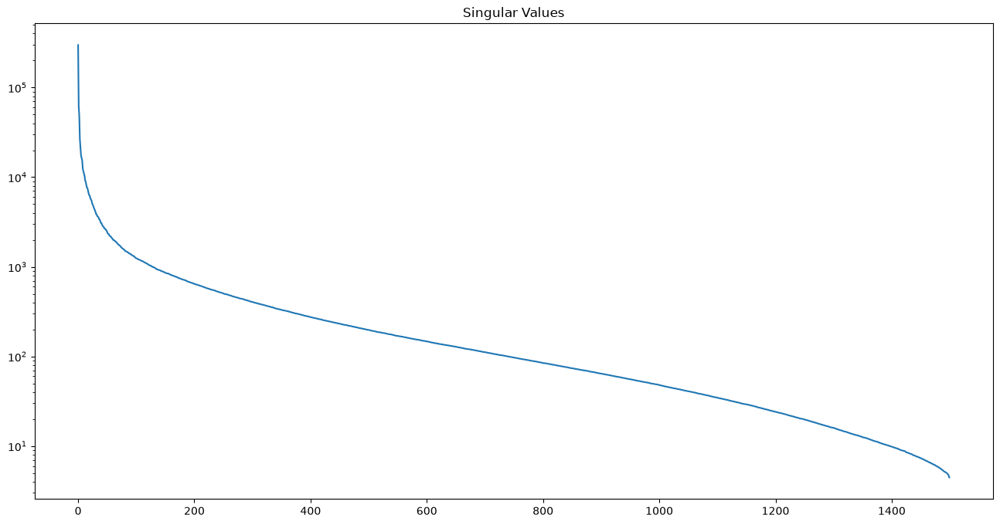

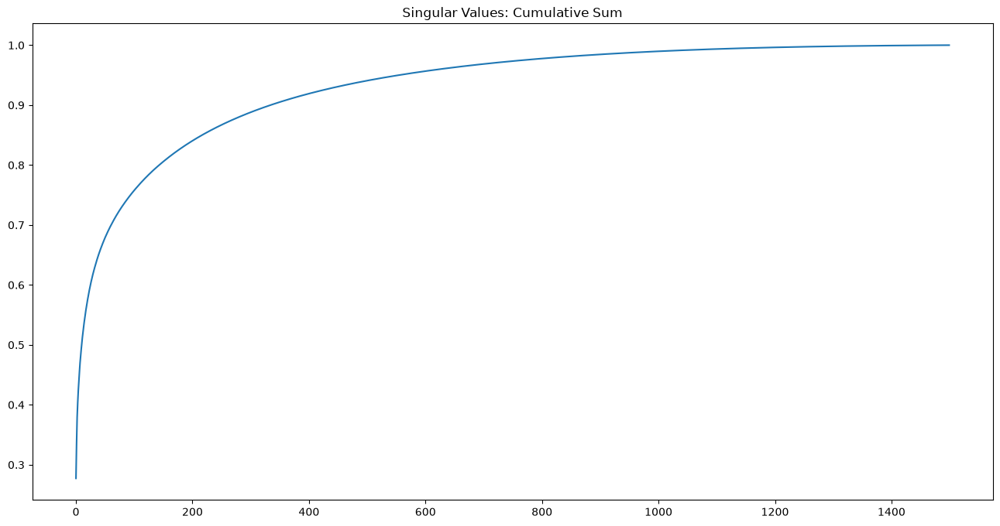

In [3]:
## f_ch01_ex02_2

plt.figure(1)
plt.semilogy(np.diag(S))
plt.title('Singular Values')
plt.show()

plt.figure(2)
plt.plot(np.cumsum(np.diag(S))/np.sum(np.diag(S)))
plt.title('Singular Values: Cumulative Sum')
plt.show()

In [18]:
import imageio.v3 as iio
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib as mpl

mpl.rcParams['animation.embed_limit'] = 500  # MB

gif_path = os.path.join('..', 'DATA', 'fun', 'what-have-they-done.gif')
A = iio.imread(gif_path)

fig, ax = plt.subplots()
img = ax.imshow(A[0])
img.set_cmap('gray')
ax.axis("off")

def update(frame):
    X = np.mean(frame, -1); # Convert RGB to grayscale
    U, S, VT = np.linalg.svd(X,full_matrices=False)
    S = np.diag(S)
    r = 100
    Xapprox = U[:,:r] @ S[0:r,:r] @ VT[:r,:]
    img.set_data(Xapprox)
    return [img]

ani = FuncAnimation(
    fig,
    update,
    frames=A,
    interval=50,
    blit=True,
    repeat=True
)

plt.close(fig)  # Prevent a separate static figure from being displayed

HTML(ani.to_jshtml())
